# Planta Física: Genetic algorithms

MA2015.202 · Team 08

- Aldo Tolentino Luna (A01668465)
- Emilio Estrada Pérez (A01770665)
- Juan Diego Rodríguez Espinoza (A01667431)

| Role | Member |
|:--|:--|
| Driver | Juan Diego |
| Reviewer | Emilio Estrada |
| Verifier | Aldo Tolentino |


Data: Recorded water demands during March 2025 

GitHub: https://github.com/Monknow/reto-planta-fisica

## 1. Problem Definition

The _Planta Física_ needs to allocate treated water to four buildings (Aulas I, Biblioteca, CEDETEC, Aulas II) to reduce the potable water consumed. If we don't provide enough treated water to meet each building's demands, then the remaining demand is fulfilled by potable water.

The total water demand of each building during March 2025 (monthly totals from the records) is:

- Aulas 1 = 847 m³
- Biblioteca = 462 m³
- Cedetec = 284.21 m³
- Aulas 2 = 683 m³

We suppose the maximum treated-water capacity for March 2025 is 1 410 m³ (a monthly total).

**Note:** The monthly capacity is a teaching assumption; it is not a partner-confirmed capacity.

All quantities in this notebook ($D_i$, $\sum_i D_i = 2276.21$ m³, $C$, $T$, $P$ and $E$) are monthly totals for March 2025, so the model applies only to this monthly exercise.

Each building has a reuse limit which represents the maximum percentage of the building's monthly demand that can be covered with treated water.

- Aulas 1 = 80%
- Biblioteca = 80%
- Cedetec = 60%
- Aulas 2 = 80%

**Note:** The reuse limits are teaching assumptions.

We can vary the reuse percentage within their limit. To describe each reuse percentage, we'll encode them together in a chromosome $k=(k_1,k_2,k_3,k_4)$ Using integers: 

- $k_1,k_2,k_4\in\{0,\ldots,80\}$ 
- $k_3\in\{0,\ldots,60\}$. 

Where $x_i=k_i/100$, so each gene is a reuse percentage in steps of one percentage point. For example, gene 60 represents 60% reuse. This means we have $81\times81\times61\times81=32\,417\,901$ combinations which we'll navigate using the genetic algorithm to find the best combination.

The next table summarizes each building's details:


| Building   | Demand $D_i$ ($m^3$) | Domain of $k_i$    | Maximum reuse |
|:-----------|---------------------:|:------------------:|--------------:|
| Aulas 1    | 847.00               | $\{0,\ldots,80\}$  | 80%           |
| Biblioteca | 462.00               | $\{0,\ldots,80\}$  | 80%           |
| Cedetec    | 284.21               | $\{0,\ldots,60\}$  | 60%           |
| Aulas 2    | 683.00               | $\{0,\ldots,80\}$  | 80%           |

In [25]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, monthly totals, March 2025
LIMITS = np.array([80, 80, 60, 80])  # integer percentage levels
SCALE = 100  # fractions = levels / SCALE
CAPACITY = 1410.0  # m3 per month (March 2025); teaching assumption, not confirmed plant capacity

## 2. The Fitness Function

Our decision variable is the reuse percentage on each building. To evaluate each combination, we'll need to define a fitness function that determines the efficiency of each chromosome. To do so, we'll define the following values:

**Treated Water:** The amount of treated water the system used, which is just the sum of the treated water for each building.

$$\text{Treated water: } T_i = D_i\frac{k_i}{100}, \qquad T= \sum_i T_i = \frac{1}{100} \sum_i D_i k_i$$

**Potable Water:** The amount of potable water we had to inject in the system to satisfy demand. It is the total demand minus the treated water the system was able to use.

$$\text{Potable water: } P_i = D_i - T_i, \qquad P=\sum_i P_i = \sum_iD_i-T$$

**Excess capacity:** The system cannot provide treated water ($T$) beyond its established capacity ($C$). Once $T$ is greater than $C$, the system becomes unfeasiable since we are using treated water we don't even have. The excess capacity represents the amount of *unavailable* treated water the system is trying to use. 

$$\text{Excess capacity: } E=\max(0,T-C)$$

In other words, once the Excess capacity is greater than zero, the system is unfesiable.

With that said, our goal is to minimize $P$ (the amount of potable water the system requires), subject to the gene domains and $T\le C$ (using the available treated water). 

To get a better sense of the efficiency of the system, instead of directly minimizing $P$, we'll minimize $F= \frac{P}{\sum D_i}$, which represents the ratio of the demand that's satisified by potable water. Our fitness function is then F where **lower fitness is better.**

Note that, if we use the current $F$ as the fitness function, we could cheat the system by ignoring the system's capacity, setting $P$ to zero and $T$ to the maximum, resulting in a perfect $F = 0$. To avoid this, whenever the system is unfeasible we set  $F=1+\frac{E}{C}$. This way, a feasible candidate has $F\le1$; an unfeasible candidate has $F>1$

We use a numerical tolerance of $10^{-8}$ m³.

### Calculations by Hand

Before running the code, let's calculate by hand three candidates. For each one we first compute the treated and potable water building by building, $T_i = D_i\frac{k_i}{100}$ and $P_i = D_i - T_i$, check that $T_i + P_i = D_i$, and then add the rows to get $T$ and $P$. All volumes are monthly totals for March 2025, in m³.

$$\sum_i D_i = D_1+D_2+D_3+D_4 = 847.00+462.00+284.21+683.00 = 2276.21\ \text{m}^3$$

1. Constant reuse: $k=(60,60,60,60)$

Every $k_i=60$, therefore $x_i = \frac{60}{100} = 0.6$. The four products are:

- $T_1 = 847 \times 0.6 = 508.200$ m³
- $T_2 = 462 \times 0.6 = 277.200$ m³
- $T_3 = 284.21 \times 0.6 = 170.526$ m³
- $T_4 = 683 \times 0.6 = 409.800$ m³

| Building | $D_i$ (m³) | $k_i$ | $x_i=k_i/100$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 60 | 0.6 | 847 × 0.6 = 508.200 | 847.00 − 508.200 = 338.800 | 508.200 + 338.800 = 847.00 ✓ |
| Biblioteca | 462.00 | 60 | 0.6 | 462 × 0.6 = 277.200 | 462.00 − 277.200 = 184.800 | 277.200 + 184.800 = 462.00 ✓ |
| Cedetec | 284.21 | 60 | 0.6 | 284.21 × 0.6 = 170.526 | 284.21 − 170.526 = 113.684 | 170.526 + 113.684 = 284.21 ✓ |
| Aulas 2 | 683.00 | 60 | 0.6 | 683 × 0.6 = 409.800 | 683.00 − 409.800 = 273.200 | 409.800 + 273.200 = 683.00 ✓ |
| **Total** | **2276.21** | | | **1365.726** | **910.484** | 1365.726 + 910.484 = 2276.21 ✓ |

$$
\begin{aligned}
& T = \sum_i T_i = 508.200+277.200+170.526+409.800 = 1365.726\ \text{m}^3 \\
& P = \sum_i P_i = 338.800+184.800+113.684+273.200 = 910.484\ \text{m}^3 \quad (= 2276.21-1365.726) \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 1365.726-1410 = -44.274 \le 0 \\
& \text{Then } E = \max(0,\ -44.274) = 0\ \text{m}^3 \\ \\

& \text{Since it is feasible } (T\le C), \text{ let's calculate the fitness function as:} \\ \\

& F = \frac{P}{\sum_i D_i} = \frac{910.484}{2276.21} = 0.4
\end{aligned}
$$

2. Zero reuse: $k = (0, 0, 0, 0)$

Every $k_i=0$, therefore $x_i = \frac{0}{100} = 0$, so every product is zero ($847 \times 0 = 462 \times 0 = 284.21 \times 0 = 683 \times 0 = 0$ m³) and each building is supplied only with potable water.

| Building | $D_i$ (m³) | $k_i$ | $x_i=k_i/100$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 0 | 0.0 | 847 × 0.0 = 0.000 | 847.00 − 0.000 = 847.000 | 0.000 + 847.000 = 847.00 ✓ |
| Biblioteca | 462.00 | 0 | 0.0 | 462 × 0.0 = 0.000 | 462.00 − 0.000 = 462.000 | 0.000 + 462.000 = 462.00 ✓ |
| Cedetec | 284.21 | 0 | 0.0 | 284.21 × 0.0 = 0.000 | 284.21 − 0.000 = 284.210 | 0.000 + 284.210 = 284.21 ✓ |
| Aulas 2 | 683.00 | 0 | 0.0 | 683 × 0.0 = 0.000 | 683.00 − 0.000 = 683.000 | 0.000 + 683.000 = 683.00 ✓ |
| **Total** | **2276.21** | | | **0.000** | **2276.210** | 0.000 + 2276.210 = 2276.21 ✓ |

$$
\begin{aligned}
& T = \sum_i T_i = 0\ \text{m}^3 \\
& P = \sum_i P_i = 2276.21-0 = 2276.21\ \text{m}^3 \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 0-1410 = -1410 \le 0 \\
& \text{Then } E = \max(0,\ -1410) = 0\ \text{m}^3 \\ \\

& \text{Since it is feasible } (T\le C), \text{ let's calculate the fitness function as:} \\ \\

& F = \frac{P}{\sum_i D_i} = \frac{2276.21}{2276.21} = 1.0
\end{aligned}
$$

3. Maximum levels in each domain: $k = (80, 80, 60, 80)$

Here $k_i=80$ for $i\in\{1,2,4\}$ and $k_3=60$, therefore $x_1=x_2=x_4=0.8$ and $x_3=0.6$. The four products are:

- $T_1 = 847 \times 0.8 = 677.600$ m³
- $T_2 = 462 \times 0.8 = 369.600$ m³
- $T_3 = 284.21 \times 0.6 = 170.526$ m³
- $T_4 = 683 \times 0.8 = 546.400$ m³

| Building | $D_i$ (m³) | $k_i$ | $x_i=k_i/100$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) | Check $T_i+P_i=D_i$ |
|:--|--:|--:|--:|--:|--:|:-:|
| Aulas 1 | 847.00 | 80 | 0.8 | 847 × 0.8 = 677.600 | 847.00 − 677.600 = 169.400 | 677.600 + 169.400 = 847.00 ✓ |
| Biblioteca | 462.00 | 80 | 0.8 | 462 × 0.8 = 369.600 | 462.00 − 369.600 = 92.400 | 369.600 + 92.400 = 462.00 ✓ |
| Cedetec | 284.21 | 60 | 0.6 | 284.21 × 0.6 = 170.526 | 284.21 − 170.526 = 113.684 | 170.526 + 113.684 = 284.21 ✓ |
| Aulas 2 | 683.00 | 80 | 0.8 | 683 × 0.8 = 546.400 | 683.00 − 546.400 = 136.600 | 546.400 + 136.600 = 683.00 ✓ |
| **Total** | **2276.21** | | | **1764.126** | **512.084** | 1764.126 + 512.084 = 2276.21 ✓ |

$$
\begin{aligned}
& T = \sum_i T_i = 677.600+369.600+170.526+546.400 = 1764.126\ \text{m}^3 \\
& P = \sum_i P_i = 169.400+92.400+113.684+136.600 = 512.084\ \text{m}^3 \quad (= 2276.21-1764.126) \\ \\

& \text{Now, is this combination feasible?} \\ \\

& E = \max(0,\,T-C) \\
& T-C = 1764.126-1410 = 354.126 > 0 \\
& \text{Then } E = \max(0,\ 354.126) = 354.126\ \text{m}^3 \\ \\

& \text{Since it is not feasible } (T>C), \text{ let's calculate the fitness function as:} \\ \\

& F = 1+\frac{E}{C} = 1+\frac{354.126}{1410} = 1.25115319
\end{aligned}
$$

In [26]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)

    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")

    treated = float(np.sum(DEMAND * genes / SCALE))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m^3

    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY

    return {
        "treated": treated,
        "potable": potable,
        "excess": excess,
        "feasible": feasible,
        "fitness": fitness,
    }

In [27]:
cases = [np.zeros(4, dtype=int), np.array([60, 60, 60, 60]), LIMITS.copy()]

for genes in cases:
    print(genes, evaluate(genes))

assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[60 60 60 60] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[80 80 60 80] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


We compare our manual values from the previous section with the output of `evaluate`. Volumes are rounded to 3 decimals (m³) and $F$ to 8 decimals. The difference column is $|\text{manual} - \text{evaluator}|$ computed with the unrounded evaluator output.

| Case $k$ | Metric | Manual value | Evaluator value | Difference |
|:--|:--|--:|--:|--:|
| $(60,60,60,60)$ | `treated` $T$ (m³) | 1365.726 | 1365.726 | $2.3\times10^{-13}$ |
| | `potable` $P$ (m³) | 910.484 | 910.484 | $1.1\times10^{-13}$ |
| | `excess` $E$ (m³) | 0.000 | 0.000 | 0 |
| | `feasible` | True | True | — (equal) |
| | `fitness` $F$ | 0.40000000 | 0.40000000 | $5.6\times10^{-17}$ |
| $(0,0,0,0)$ | `treated` $T$ (m³) | 0.000 | 0.000 | 0 |
| | `potable` $P$ (m³) | 2276.210 | 2276.210 | 0 |
| | `excess` $E$ (m³) | 0.000 | 0.000 | 0 |
| | `feasible` | True | True | — (equal) |
| | `fitness` $F$ | 1.00000000 | 1.00000000 | 0 |
| $(80,80,60,80)$ | `treated` $T$ (m³) | 1764.126 | 1764.126 | $2.3\times10^{-13}$ |
| | `potable` $P$ (m³) | 512.084 | 512.084 | $1.1\times10^{-13}$ |
| | `excess` $E$ (m³) | 354.126 | 354.126 | $2.3\times10^{-13}$ |
| | `feasible` | False | False | — (equal) |
| | `fitness` $F$ | 1.25115319 | 1.25115319 | $1.5\times10^{-9}$ |

All five keys agree for the three cases. The nonzero differences of order $10^{-13}$ come from floating-point representation in the code, and the $1.5\times10^{-9}$ in $F$ for $(80,80,60,80)$ comes from rounding our manual value to 8 decimals (the evaluator gives $1.2511531914\ldots$). None of them come from the model.

We also see that it isn't feasible to set the reuse percentage to the maximum, so we'll have to make sacrifices about which genes to use. From our manual tests, the $[60, 60, 60, 60]$ chromosome had the best fitness.

## 3. We generate a population

We define the population a the list of candidates. We sample each gene within its domain, including both endpoints. Note that sampling does not guarantee a feasible solution. However, we hope the fitness punishment for unfeasible solutions will rule out those chromosomes.

In [28]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)


rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[ 7 62 39 35] 0.694394673602172
[35 69  5 56] 0.5554362295218807
[16  7 32 79] 0.6492515189723268
[59 61 43 63] 0.41391598314742495


## 4. We select parents through tournaments

We sample two distinct candidates and choose the one with lower $F$. We repeat the process to select another parent. Note that the same individual can win several tournaments. Selection favors lower fitness without always sorting the entire population. 

See that we return a copy to protect the original.

In [29]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()


parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[35 69  5 56] [35 69  5 56]


## 5. We combine information through one-point crossover

We choose a cut between gene positions and join the beginning of one parent with the end of the other. Note that each gene keeps its position, so the first gene always describes Aulas 1, the second Biblioteca, and so on. For parents $(60,60,60,60)$ and $(80,20,40,30)$ with cut 2, we obtain $(60,60,40,30)$.

Since every gene comes from a parent, the child always stays inside the gene domains. However, nothing guarantees it respects the capacity, so a child can be unfeasible and we let $F$ punish it. Also note that if both tournaments return the same individual, the child is just a copy of that parent.

This is the supplied **baseline** crossover. In Section 12 we keep it unchanged and compare it with a team variant.

In [30]:
def crossover(
    parent_a: np.ndarray, parent_b: np.ndarray, rng: np.random.Generator
) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))


child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[35 69  5 56] {'treated': 1011.9205000000001, 'potable': 1264.2894999999999, 'excess': 0.0, 'feasible': True, 'fitness': 0.5554362295218807}


## 6. We introduce variation through mutation

Crossover only recombines genes that already exist in the population, so we need mutation to try new values. We apply the probability to **each gene** instead of the whole chromosome, and a selected gene moves one valid level (one percentage point) up or down. At zero it can only go up, and at its maximum it can only go down.

With $p=0.25$ and four genes, we expect one mutated gene per child on average, but not exactly one: some children won't mutate at all and others will mutate two or more. Note that mutation can improve or worsen $F$, and it can even turn a feasible child into an unfeasible one.

In [31]:
def mutate(
    child: np.ndarray, probability: float, rng: np.random.Generator
) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result


mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[35 69  5 56] [35 69  5 57] {'treated': 1018.7505000000001, 'potable': 1257.4595, 'excess': 0.0, 'feasible': True, 'fitness': 0.552435627644198}


## 7. We replace the population and preserve one elite

We copy the best individual without changing it and fill the remaining positions with children, so the population size stays constant. This is called elitism: the best fitness can never get worse from one generation to the next. Note that this doesn't mean we found the optimum, only that we don't lose the best candidate we've seen.

See that we copy the elite and only mutate the children, so mutating a child never changes its parent or the elite. If no child beats the elite, the best fitness stays the same, which is what we see in the demo below.

In [32]:
def next_generation(
    population: list,
    probability: float,
    rng: np.random.Generator,
    crossover_fn=crossover,
) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover_fn(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement


replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.41391598314742495
0.41391598314742495


## 8. We complete the cycle

We initialize the population and then repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the best $F$ at initialization and after each generation, so 20 generations give us 21 values. Don't expect an improvement at every step: because of elitism the curve never goes up, but it can stay flat for many generations.

In [33]:
def run_ga(
    population_size: int = 20,
    generations: int = 20,
    mutation_probability: float = 0.25,
    seed: int = 42,
    crossover_fn=crossover,
) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng, crossover_fn)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. We run the baseline and a mutation variation

We use 20 individuals, 20 generations and seed 42. In the variation, we change only the per-gene mutation probability from 0.25 to 0.50, and keep the data, gene domains, capacity and all other parameters fixed. Note that this compares two executions; it doesn't establish that one configuration is better than the other in general.

This is the same-code comparison we need for the Final, and it uses the supplied one-point crossover. The Development comparison, where we change one operator and keep $p_m=0.25$ in both versions, is in Section 12.

In [34]:
CONFIG = {"population_size": 20, "generations": 20, "mutation_probability": 0.25, "seed": 42}

baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)

for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / SCALE)
    print(result["metrics"])

p=0.25 genes = [59 59 32 80] fractions = [0.59 0.59 0.32 0.8 ]
{'treated': 1409.6571999999999, 'potable': 866.5528000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.3806998475536089}
p=0.50 genes = [66 61 44 65] fractions = [0.66 0.61 0.44 0.65]
{'treated': 1409.8424, 'potable': 866.3676, 'excess': 0.0, 'feasible': True, 'fitness': 0.3806184842347587}


## 10. We visualize and interpret

In the plot, the horizontal axis is the generation and the vertical axis is the best fitness. A decrease means improvement, and a flat segment means no child beat the best value we were already keeping. Note that a descending curve alone doesn't tell us the solution is valid, so we always connect it back to feasibility and water volumes.

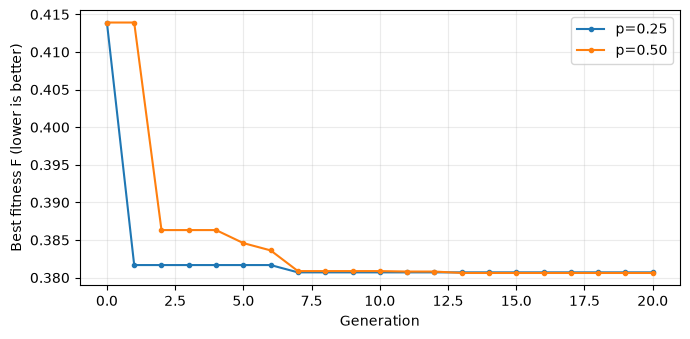

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel="Generation", ylabel="Best fitness F (lower is better)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

The only parameter we changed is the mutation probability, from $p=0.25$ to $p=0.50$; both runs use the baseline one-point crossover. The next table compares the best chromosome of each run:

| | $p=0.25$ | $p=0.50$ |
|:--|--:|--:|
| Best chromosome $k$ | $(59,59,32,80)$ | $(66,61,44,65)$ |
| Reuse per building | 59%, 59%, 32%, 80% | 66%, 61%, 44%, 65% |
| Treated water $T$ ($m^3$) | 1409.657 | 1409.842 |
| Potable water $P$ ($m^3$) | 866.553 | 866.368 |
| Excess capacity $E$ ($m^3$) | 0 | 0 |
| Best fitness $F$ | 0.38070 | 0.38062 |
| Feasible | Yes | Yes |

Both runs end with a feasible solution, and both use almost all of the treated water available: they stay less than 0.5 $m^3$ below the capacity of 1 410 $m^3$. Compared to our best hand calculation, $(60,60,60,60)$ with $F=0.4$, both improve the fitness, since they take better advantage of the capacity. The finer gene resolution (steps of one percentage point instead of ten) lets the algorithm get closer to $C$.

Both runs start from the same best individual, with $F\approx0.41392$. With $p=0.25$ the best fitness drops to $0.38167$ in generation 1, improves once more in generation 7, and stays flat for the rest of the run. With $p=0.50$ the first improvement appears in generation 2, and then smaller improvements follow until generation 13, after which the curve stays flat. In both cases, a plateau means that no child was better than the elite, and not that the search is finished.

Note that, for a feasible candidate, $F=\frac{P}{\sum_i D_i}=1-\frac{T}{\sum_i D_i}$. In other words, the algorithm is really looking for the combination whose $T$ gets as close as possible to $C$ without going over it. Many different chromosomes can do that, which is why the two runs end with different genes and almost the same $F$.

The difference between runs is $\approx0.00008$ in $F$, which is about 0.19 $m^3$ of potable water over March 2025. With a single seed per configuration, we can't say that $p=0.50$ is better than $p=0.25$. We only know that, with seed 42, the variant ended slightly better, while the baseline reached most of its improvement sooner. We would need several seeds to say anything more general. We also don't claim either result is the global optimum, because the GA doesn't guarantee it.

## 11. We check reproduction

We repeat the baseline with the same seed and check that the genes and the history match. We also restart the kernel and run the notebook from top to bottom, to make sure the results don't depend on cells we executed earlier. Note that this is a technical check, not a third experimental configuration. The last assertion checks elitism: the best fitness never goes up from one generation to the next.

In [36]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print("Reproduction and elitism checked.")

Reproduction and elitism checked.


## 12. Development: we compare three versions

We preserve the supplied baseline and add two team changes, one at a time, so each comparison isolates a single change:

| Version | Gene domains | $x_i$ | Crossover | Compared with |
|:--|:--|:--|:--|:--|
| **V1** (supplied baseline) | $\{0,\ldots,8\}$, Cedetec $\{0,\ldots,6\}$ | $k_i/10$ | one-point | — |
| **V2** | $\{0,\ldots,80\}$, Cedetec $\{0,\ldots,60\}$ | $k_i/100$ | one-point | V1: only the resolution changes |
| **V3** | $\{0,\ldots,80\}$, Cedetec $\{0,\ldots,60\}$ | $k_i/100$ | **midpoint** | V2: only the crossover operator changes |

Selection (Section 4), mutation (Section 6) and elitism (Section 7) are the same code in all three versions. Note that mutation moves a gene by one level, so in V1 a mutation step is 10 percentage points and in V2 and V3 it is 1 percentage point; this is part of the resolution change, not a change to the operator. Sections 9–11 use V2 and the supplied one-point `crossover`, which is still the default of `next_generation` and `run_ga`.

### 12.1 Limitations and hypotheses

**V1 → V2: resolution.** *Limitation:* with steps of 10%, the treated water $T$ can only take a few values, and only one chromosome of the 5 103 gets within 0.02 m³ of the capacity. *Hypothesis:* with steps of 1% there are many more chromosomes close to $T=C$ (32 417 901 combinations), so the GA should end closer to the capacity, with a lower $F$. *Risk:* the search space is more than 6 000 times larger, and mutation moves only 1 percentage point at a time.

**V2 → V3: crossover.** *Limitation:* one-point crossover only *copies* genes, so every gene of the child is a value that one of the parents already had. With 81 levels per gene, the only way to reach new values is mutation, one percentage point at a time. With four genes there are also only three possible cuts. *Change:* we interpolate linearly between both parents and keep the half value of each gene, rounding to the nearest integer (a .5 goes up):

$$c_i = \operatorname{round}\left(\frac{a_i + b_i}{2}\right) = \left\lfloor\frac{a_i+b_i+1}{2}\right\rfloor$$

For parents $(60,60,60,60)$ and $(80,20,40,31)$ we obtain $(70,40,50,46)$, where $45.5 \to 46$. The midpoint of two values in a domain is in that domain, so the child always respects the gene limits; the capacity is still handled by $F$.

*Hypothesis:* for a feasible candidate, $F = 1 - T/\sum_i D_i$, so the best solutions lie just below the boundary $T = C$. Since $T$ is linear in the genes, the child's treated water is approximately the average of its parents': $T(c) \approx \frac{T(a)+T(b)}{2}$. If one parent is below the capacity and the other above it, the child falls between them, closer to the boundary. We therefore expect V3 to reach a lower $F$ than V2 with seed 42. *Risk:* averaging pulls every child towards the middle of its parents, so the population can lose diversity quickly (premature convergence).

In [37]:
def crossover_midpoint(
    parent_a: np.ndarray, parent_b: np.ndarray, rng: np.random.Generator
) -> np.ndarray:
    """Create one child from the gene-wise midpoint of both parents, rounded half up."""
    # rng is kept so both operators share the same signature; the midpoint is deterministic.
    return (parent_a + parent_b + 1) // 2


example_a, example_b = np.array([60, 60, 60, 60]), np.array([80, 20, 40, 31])
example_child = crossover_midpoint(example_a, example_b, rng_demo)
print(example_a, "+", example_b, "->", example_child)
assert np.array_equal(example_child, [70, 40, 50, 46])  # 45.5 rounds up to 46
assert np.all(example_child >= 0) and np.all(example_child <= LIMITS)

[60 60 60 60] + [80 20 40 31] -> [70 40 50 46]


### 12.2 We run the three versions under the same conditions

All three runs use the same data, capacity, tournament selection, mutation ($p_m=0.25$), elitism, population (20), generations (20) and seed (42). `resolution` temporarily switches the gene domains and the scale used by every function, and restores them afterwards, so V1 runs exactly the supplied code. The assertions check that V1 reproduces the supplied baseline result $(7,4,3,8)$ and that V2 matches the Section 9 baseline.

In [38]:
from contextlib import contextmanager


@contextmanager
def resolution(limits, scale):
    """Temporarily change the gene domains and scale used by every GA function."""
    global LIMITS, SCALE
    saved = LIMITS, SCALE
    LIMITS, SCALE = np.array(limits), scale
    try:
        yield
    finally:
        LIMITS, SCALE = saved


VERSIONS = {
    "V1: 0-8, one-point": dict(limits=[8, 8, 6, 8], scale=10, crossover_fn=crossover),
    "V2: 0-80, one-point": dict(limits=[80, 80, 60, 80], scale=100, crossover_fn=crossover),
    "V3: 0-80, midpoint": dict(limits=[80, 80, 60, 80], scale=100, crossover_fn=crossover_midpoint),
}


def run_version(name: str, **config) -> dict:
    """Run run_ga with the gene domains, scale and crossover of one version."""
    version = VERSIONS[name]
    with resolution(version["limits"], version["scale"]):
        result = run_ga(**config, crossover_fn=version["crossover_fn"])
    result["fractions"] = result["genes"] / version["scale"]
    return result


DEV_CONFIG = {"population_size": 20, "generations": 20, "mutation_probability": 0.25, "seed": 42}
dev_results = {name: run_version(name, **DEV_CONFIG) for name in VERSIONS}

for name, result in dev_results.items():
    metrics = result["metrics"]
    treated_i = DEMAND * result["fractions"]
    print(f"{name}: genes = {result['genes']}")
    print(f"  {'Building':<11}{'k_i':>5}{'x_i':>6}{'T_i (m3)':>12}{'P_i (m3)':>12}")
    for b, k, x, t, d in zip(BUILDINGS, result["genes"], result["fractions"], treated_i, DEMAND):
        print(f"  {b:<11}{k:>5}{x:>6.2f}{t:>12.3f}{d - t:>12.3f}")
    print(f"  T = {metrics['treated']:.3f}  P = {metrics['potable']:.3f}  E = {metrics['excess']:.3f}"
          f"  feasible = {metrics['feasible']}  F = {metrics['fitness']:.8f}")
    print()

# V1 is exactly the supplied baseline, V2 is the Section 9 baseline, and the global domains are restored
np.testing.assert_array_equal(dev_results["V1: 0-8, one-point"]["genes"], [7, 4, 3, 8])
np.testing.assert_array_equal(dev_results["V2: 0-80, one-point"]["history"], baseline["history"])
assert np.array_equal(LIMITS, [80, 80, 60, 80]) and SCALE == 100

V1: 0-8, one-point: genes = [7 4 3 8]
  Building     k_i   x_i    T_i (m3)    P_i (m3)
  AULAS 1        7  0.70     592.900     254.100
  BIBLIOTECA     4  0.40     184.800     277.200
  CEDETEC        3  0.30      85.263     198.947
  AULAS 2        8  0.80     546.400     136.600
  T = 1409.363  P = 866.847  E = 0.000  feasible = True  F = 0.38082910

V2: 0-80, one-point: genes = [59 59 32 80]
  Building     k_i   x_i    T_i (m3)    P_i (m3)
  AULAS 1       59  0.59     499.730     347.270
  BIBLIOTECA    59  0.59     272.580     189.420
  CEDETEC       32  0.32      90.947     193.263
  AULAS 2       80  0.80     546.400     136.600
  T = 1409.657  P = 866.553  E = 0.000  feasible = True  F = 0.38069985

V3: 0-80, midpoint: genes = [63 68 44 64]
  Building     k_i   x_i    T_i (m3)    P_i (m3)
  AULAS 1       63  0.63     533.610     313.390
  BIBLIOTECA    68  0.68     314.160     147.840
  CEDETEC       44  0.44     125.052     159.158
  AULAS 2       64  0.64     437.120     245.

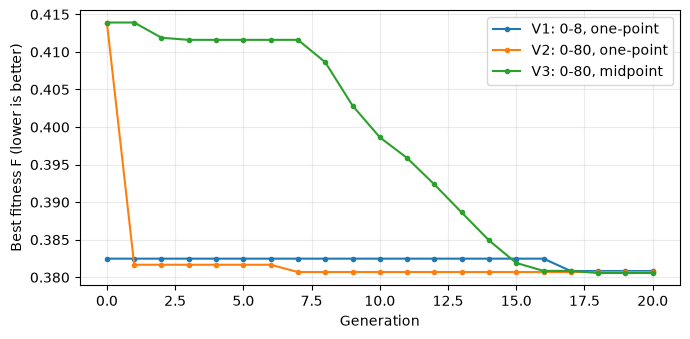

In [39]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, result in dev_results.items():
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=name)
ax.set(xlabel="Generation", ylabel="Best fitness F (lower is better)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

### 12.3 We compare the final chromosomes

| | V1: 0–8, one-point | V2: 0–80, one-point | V3: 0–80, midpoint |
|:--|--:|--:|--:|
| Final chromosome $k$ | $(7,4,3,8)$ | $(59,59,32,80)$ | $(63,68,44,64)$ |
| Reuse per building | 70%, 40%, 30%, 80% | 59%, 59%, 32%, 80% | 63%, 68%, 44%, 64% |
| $T_i$ Aulas 1 / Biblioteca / Cedetec / Aulas 2 (m³) | 592.900 / 184.800 / 85.263 / 546.400 | 499.730 / 272.580 / 90.947 / 546.400 | 533.610 / 314.160 / 125.052 / 437.120 |
| $P_i$ Aulas 1 / Biblioteca / Cedetec / Aulas 2 (m³) | 254.100 / 277.200 / 198.947 / 136.600 | 347.270 / 189.420 / 193.263 / 136.600 | 313.390 / 147.840 / 159.158 / 245.880 |
| Treated water $T$ (m³) | 1409.363 | 1409.657 | 1409.942 |
| Potable water $P$ (m³) | 866.847 | 866.553 | 866.268 |
| Unused capacity $C-T$ (m³) | 0.637 | 0.343 | 0.058 |
| Excess capacity $E$ (m³) | 0 | 0 | 0 |
| Feasible | Yes | Yes | Yes |
| Best fitness $F$ | 0.38082910 | 0.38069985 | 0.38057455 |

**Result with seed 42.** All three versions end feasible, and each one ends a little better than the previous one. V2 uses 0.294 m³ less potable water than V1, and V3 uses 0.285 m³ less than V2. In this run, both hypotheses hold.

## 13. Keep evidence in the same notebook

- **Research (15%)**: A1 formulation and assumptions (60/100); A2 hand calculation and comparison with the evaluator (40/100).
- **Development (15%)**: B1 functional cycle and justified substantive modification of one operator (70/100); B2 reproducibility and controlled baseline/variant comparison (30/100). Use $p_m=0.25$ for both versions.
- **Final (30%)**: C1 explanation of one generation (40/100); C2 same-code comparison of mutation probabilities 0.25/0.50 and its plot (35/100); C3 physical interpretation and model limitations (25/100).

For Final, retain earlier sections and add your team's explanation. Identify the supplied baseline and any team changes. If you still have only the baseline, identify it as unmodified and complete the Final analysis; the Development penalty will not be applied again. Keep the supplied environment files beside the notebook. The written team code examination will contribute 10% and the individual article examination will contribute 30%. Consult the [guide](challenge_guide_planta_fisica.pdf) and the detailed instructions in Canvas for performance levels and dates.

## Provenance and environment

We use the four March 2025 records from the supplied water-consumption data and the instructor-calibrated teaching limits. Notebook metadata retains the records and source hashes. The monthly case and code are self-contained.

With Python 3.12-3.14 and the supplied environment files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs the calculations and Matplotlib draws the plot. Results describe this teaching model; they do not establish a validated hydraulic or sanitary recommendation.